# Multi-Region REE Prospectivity — No-Geochemistry (RF + DevNet)

## 1. Configuration

In [17]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from skimage.feature import graycomatrix, graycoprops
import torch
import torch.nn as nn
import torch.optim as optim
import rasterio
from rasterio.mask import mask as rio_mask
import pyproj

BASE = '../dataset'

_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

REGIONS = {
    'Cordilleran': {
        'geo':     '../geochem/Geochemistry_Cordilleran_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Superior': {
        'geo':     '../geochem/Geochemistry_Superior_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Grenville': {
        'geo':     '../geochem/Geochemistry_Grenville_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv',
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
}

PROJECTED_CRS  = 'EPSG:3978'  # Canada Atlas Lambert (metres)
BUFFER_KM      = 10.0         # min distance from any REE deposit → negative sample
N_BACKGROUND   = 400          # max negative samples per region
GRID_DEG       = 0.1          # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED    = 42
DN_SEED        = 42
DN_EPOCHS      = 250
DN_BATCH       = 32
DN_RESTARTS    = 3      # per-fold restarts averaged to reduce init variance
DN_MARGIN      = 5.0   # deviation margin; 8.0 is too demanding for few positives


## 1.5. Preprocess — Clip National Rasters to Study Areas

Runs once; clipped files are cached in `clipped/<region>/`. Delete the folder to force re-clip.

In [18]:
CLIP_DIR = 'clipped'

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

def preprocess_rasters(name, cfg):
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir   = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} ...')
            clip_raster(path, boundary, out_path)
        clipped[feat] = out_path
    return clipped



def preprocess_vectors(name, cfg):
    """Clip H3 Grid polygon layer to study area and cache as GeoPackage."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir  = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    h3_path = cfg.get('h3_grid')
    if not h3_path:
        return {}
    out_path = os.path.join(out_dir, 'h3_grid.gpkg')
    if not os.path.exists(out_path):
        print(f'  clipping H3 Grid ({name}) ...')
        h3 = gpd.read_file(h3_path)
        gpd.clip(h3.to_crs('EPSG:4326'), boundary).to_file(out_path, driver='GPKG')
    else:
        print(f'  cached  H3 Grid ({name})')
    return {'h3_grid': out_path}
print('Clipping rasters and H3 Grid to study area boundaries ...')
CLIPPED_RASTERS = {}
CLIPPED_VECTORS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS[name] = preprocess_rasters(name, cfg)
    CLIPPED_VECTORS[name] = preprocess_vectors(name, cfg)
print('\nDone.')


Clipping rasters and H3 Grid to study area boundaries ...

[Cordilleran]
  cached  H3 Grid (Cordilleran)

[Superior]
  cached  H3 Grid (Superior)

[Grenville]
  cached  H3 Grid (Grenville)

Done.


## 2. Helper Functions

In [19]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def normalize_proximity(dist_arr):
    """Return 1 - (d-dmin)/(dmax-dmin); closer = higher value."""
    dmin, dmax = dist_arr.min(), dist_arr.max()
    return 1.0 - (dist_arr - dmin)/(dmax - dmin) if dmax > dmin else np.zeros_like(dist_arr)


## 3. Feature-Extraction Functions

In [20]:
# ── 3a. Positive / negative sample points ─────────────────────────────────
def make_points(cfg, rng):
    """Positive = REE deposits within outline.
    Negative = grid points within outline that are >BUFFER_KM from any deposit."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    # Generate regular grid inside boundary
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    # Filter: must be > BUFFER_KM from any deposit
    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    # Keep ALL candidates; cosine selection happens after feature extraction
    candidates = grid_in[min_dep_dist > BUFFER_KM][['lat','lon']].copy()
    candidates['label'] = -1  # -1 = unselected candidate

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts


# ── 3b. Proximity to line features (faults, passive margins) ──────────────
def add_proximity_lines(pts, geojson_path, col_prefix):
    gdf  = gpd.read_file(geojson_path).to_crs(PROJECTED_CRS)
    su   = gdf.geometry.union_all() if hasattr(gdf.geometry,'union_all') else gdf.geometry.unary_union
    g    = gpd.GeoDataFrame(pts.copy(),
               geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
               crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dist = g.geometry.apply(lambda p: p.distance(su)).values.astype(float)
    pts[f'{col_prefix}_dist_m']    = dist
    pts[f'{col_prefix}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3c. Proximity to point features (worms) using KDTree ──────────────────
def build_worm_trees(worm_paths):
    """Load each worm file once, project, and build a cKDTree. Returns dict of trees."""
    trees = {}
    for name, path in worm_paths.items():
        print(f'  loading worms: {name} ...')
        w = gpd.read_file(path).to_crs(PROJECTED_CRS)
        coords = np.column_stack([w.geometry.x.values, w.geometry.y.values])
        trees[name] = cKDTree(coords)
        print(f'    {len(w):,} points  tree built')
    return trees

def add_proximity_worms(pts, worm_trees):
    g = gpd.GeoDataFrame(pts.copy(),
            geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    qcoords = np.column_stack([g.geometry.x.values, g.geometry.y.values])
    for name, tree in worm_trees.items():
        dist, _ = tree.query(qcoords, k=1)
        dist = dist.astype(float)
        pts[f'worm_{name}_dist_m']    = dist
        pts[f'worm_{name}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3d. Raster sampling ────────────────────────────────────────────────────
def add_rasters(pts, raster_layers):
    for feat, path in raster_layers.items():
        with rasterio.open(path) as src:
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values
            vals = np.array([v[0] for v in src.sample(zip(xs,ys))], dtype=float)
            if src.nodata is not None:
                vals[vals == src.nodata] = np.nan
        pts[feat] = vals
    return pts


# ── 3e. Terrane attributes via point-in-polygon on H3 Grid ───────────────
# Geological era → ordinal integer (older = smaller value)
_ERA_ORDER = {'Archean': 0, 'Proterozoic': 1, 'Paleozoic': 2,
              'Mesozoic': 3, 'Cenozoic': 4}

def add_terrane_h3(pts, h3_path):
    """Point-in-polygon join with clipped H3 Grid.
    Extracts geo_era (ordinal age) and lith_code (encoded lithology)."""
    if not h3_path or not os.path.exists(h3_path):
        print('  H3 Grid not found — skipping terrane features')
        return pts
    h3 = gpd.read_file(h3_path)[['EraMaxMjr', 'LithMajor', 'geometry']]
    g  = gpd.GeoDataFrame(pts.copy(),
             geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
             crs='EPSG:4326')
    joined = gpd.sjoin(g, h3, how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]

    # Encode era as ordinal; NA / unknown → NaN
    pts['geo_era'] = joined['EraMaxMjr'].map(_ERA_ORDER).values

    # Encode lithology as integer label
    lith_vals = joined['LithMajor'].replace({'NA': None, '': None})
    pts['lith_code'] = lith_vals.astype('category').cat.codes.replace(-1, float('nan')).values
    return pts

# ── 3f. Cosine-dissimilarity negative selection ──────────────────────────
def select_negatives_cosine(pts, feat_cols, n_neg):
    """From candidates (label=-1), select the n_neg points whose feature
    vector is most cosine-dissimilar from the positive sample centroid.
    Falls back to random if too few candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values

    # Impute + standardize for cosine comparison
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)

    # Mean positive vector (unit-normalised)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)

    # Cosine similarity of each candidate with the positive centroid
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm   # shape (n_cands,)

    # Select the n_neg most dissimilar (lowest cosine similarity)
    cand_idx = np.where(cand_mask)[0]
    n_select = min(n_neg, len(cand_idx))
    top      = np.argsort(cos_sim)[:n_select]   # ascending → most dissimilar first
    selected = cand_idx[top]

    # Build final table: positives + selected negatives (relabelled 0)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    pts_out = pts.iloc[keep].copy().reset_index(drop=True)
    pts_out.loc[pts_out['label'] == -1, 'label'] = 0
    print(f'  cosine selection: kept {n_select} / {len(cand_idx)} candidates')
    return pts_out


# ── 3f-2. Mixed (cosine + random) negative selection ─────────────────────
def select_negatives_mixed(pts, feat_cols, n_neg, cosine_frac=0.5, seed=42):
    """cosine_frac of n_neg from most cosine-dissimilar candidates;
    remainder drawn uniformly at random."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm
    n_cos    = int(n_neg * cosine_frac)
    n_rand   = n_neg - n_cos
    cos_sel  = cand_idx[np.argsort(cos_sim)[:n_cos]]
    remain   = np.setdiff1d(cand_idx, cos_sel)
    rand_sel = np.random.RandomState(seed).choice(
                   remain, size=min(n_rand, len(remain)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], cos_sel, rand_sel])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  mixed selection: {n_cos} cosine + {len(rand_sel)} random / {len(cand_idx)} candidates')
    return out


# ── 3f-3. Pure random negative selection ─────────────────────────────────
def select_negatives_random(pts, n_neg, seed=42):
    """Uniform random selection from buffer-outside candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    selected  = np.random.RandomState(seed).choice(
                    cand_idx, size=min(n_neg, len(cand_idx)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  random selection: kept {len(selected)} / {len(cand_idx)} candidates')
    return out


## 3g. GLCM Texture Features

For each of the four key geophysical rasters, extract a 5×5-pixel neighbourhood
patch around every sample point, quantise to 8 gray levels, and compute four
GLCM statistics (contrast, homogeneity, energy, correlation) averaged over
four directions (0°, 45°, 90°, 135°).  Adds 4 rasters × 4 statistics = **16
columns** per point.

In [21]:
# ── 3g. GLCM texture feature extraction ───────────────────────────────────
GLCM_RASTERS    = ['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']
GLCM_PATCH_HALF = 2                                       # → 5×5 pixel window
GLCM_LEVELS     = 8                                       # quantisation bins
GLCM_PROPS      = ['contrast', 'homogeneity', 'energy', 'correlation']
GLCM_ANGLES     = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]


def add_glcm_features(pts, raster_layers,
                      patch_half=GLCM_PATCH_HALF, n_levels=GLCM_LEVELS):
    """Compute GLCM statistics from a neighbourhood patch around each point.

    Reads each raster once, quantises globally to n_levels using the
    2nd–98th percentile, then extracts a (2*patch_half+1)² window for every
    sample.  Points whose window contains fewer than (patch_half+1)² valid
    pixels receive NaN (imputed later by the median imputer).
    """
    rasters_to_use = [k for k in GLCM_RASTERS if k in raster_layers]

    for feat in rasters_to_use:
        path = raster_layers[feat]
        col_buffers = {f'{feat}_glcm_{p}': [] for p in GLCM_PROPS}

        with rasterio.open(path) as src:
            # Project sample coords to raster CRS
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs(
                    'EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values

            # Read full band into memory (clipped rasters are small)
            data = src.read(1).astype(float)
            nd   = src.nodata
            if nd is not None:
                data[data == nd] = np.nan

            # Global 2–98th-percentile quantisation to [0, n_levels-1]
            valid = np.isfinite(data)
            if valid.any():
                vmin = float(np.nanpercentile(data[valid], 2))
                vmax = float(np.nanpercentile(data[valid], 98))
                scaled = np.clip(
                    (data - vmin) / (vmax - vmin + 1e-9) * (n_levels - 1),
                    0, n_levels - 1,
                )
                data_q = np.where(valid, np.round(scaled).astype(np.uint8), 255)
            else:
                data_q = np.zeros(data.shape, dtype=np.uint8)

            H, W      = data_q.shape
            min_valid = (patch_half + 1) ** 2  # minimum usable pixels

            for xi, yi in zip(xs, ys):
                try:
                    row, col = src.index(xi, yi)
                except Exception:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                r0 = max(row - patch_half, 0)
                r1 = min(row + patch_half + 1, H)
                c0 = max(col - patch_half, 0)
                c1 = min(col + patch_half + 1, W)
                patch = data_q[r0:r1, c0:c1].copy()

                valid_px = patch[patch != 255]
                if len(valid_px) < min_valid:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                # Fill nodata pixels with local median before GLCM
                if np.any(patch == 255):
                    patch[patch == 255] = int(np.median(valid_px))

                glcm = graycomatrix(
                    patch, distances=[1], angles=GLCM_ANGLES,
                    levels=n_levels, symmetric=True, normed=True,
                )
                for p in GLCM_PROPS:
                    col_buffers[f'{feat}_glcm_{p}'].append(
                        float(graycoprops(glcm, p).mean()))

        for col_name, vals in col_buffers.items():
            pts[col_name] = vals

        print(f'    GLCM: {feat} → {len(GLCM_PROPS)} texture features')

    return pts


## 4. Build Region Feature Table

In [22]:
def build_region(name, cfg, worm_trees):
    print(f'\n[{name}] building features ...')
    rng = np.random.default_rng(RANDOM_SEED)

    pts = make_points(cfg, rng)

    print('  extracting terrane attributes (H3 Grid) ...')
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))

    print('  computing fault proximity ...')
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')

    print('  computing passive margin proximity ...')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')

    print('  computing worm proximity ...')
    pts = add_proximity_worms(pts, worm_trees)

    print('  sampling rasters ...')
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print('  extracting GLCM texture features ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    # Drop candidates where ALL rasters are NaN (outside raster coverage)
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = pts[pts[raster_cols].notna().any(axis=1)].reset_index(drop=True)

    # Cosine-dissimilarity negative selection
    feat_cols_sel = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                     if c in pts.columns]
    print('  selecting negatives (50% cosine + 50% random) ...')
    pts = select_negatives_mixed(pts, feat_cols_sel, N_BACKGROUND, cosine_frac=0.5)

    npos = int((pts['label']==1).sum())
    nneg = int((pts['label']==0).sum())
    print(f'  final: {npos} positive + {nneg} negative | {pts.shape[1]} features')

    pts.to_csv(f'{name}_features_no_geochem.csv', index=False)
    return pts


## 5. Feature Matrix

In [23]:
PROXIMITY_COLS = [
    'fault_proximity', 'margin_proximity',
    'worm_shallow_grav_proximity', 'worm_deep_grav_proximity',
    'worm_shallow_mag_proximity',  'worm_deep_mag_proximity',
]
TERRANE_COLS = ['geo_era', 'lith_code']

# GLCM columns derived from the constant definitions in cell 3g
GLCM_COLS = [
    f'{r}_glcm_{p}'
    for r in GLCM_RASTERS
    for p in GLCM_PROPS
]


def feature_matrix(pts, raster_cols, scaler=None, imputer=None, fit=True):
    feat_cols = PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
    feat_cols = [c for c in feat_cols if c in pts.columns]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values

    if imputer is None:
        imputer = SimpleImputer(strategy='median')
    if scaler is None:
        scaler = StandardScaler()

    if fit:
        X = imputer.fit_transform(X)
        X = scaler.fit_transform(X)
    else:
        X = imputer.transform(X)
        X = scaler.transform(X)

    return X, y, feat_cols, scaler, imputer


## 6. Random Forest Model

In [ ]:
def run_rf(pts, raster_cols, name):
    X, y, feat_cols, scaler, imputer = feature_matrix(pts, raster_cols)

    rf = RandomForestClassifier(n_estimators=300, max_features='sqrt',
                                class_weight='balanced', random_state=RANDOM_SEED)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    scores = cross_validate(rf, X, y, cv=cv,
                            scoring=['roc_auc','average_precision'], return_train_score=False)
    print(f'[{name}] RF 5-fold  AUC={scores["test_roc_auc"].mean():.3f}±{scores["test_roc_auc"].std():.3f}',
          f'  AP={scores["test_average_precision"].mean():.3f}±{scores["test_average_precision"].std():.3f}')

    rf.fit(X, y)

    # ── OOB AUC curve — RF analog of a training/loss curve ───────────────
    tree_steps = list(range(10, 310, 10))
    rf_oob = RandomForestClassifier(
        n_estimators=1, max_features='sqrt', class_weight='balanced',
        random_state=RANDOM_SEED, oob_score=True, warm_start=True)
    oob_aucs = []
    for n in tree_steps:
        rf_oob.set_params(n_estimators=n)
        rf_oob.fit(X, y)
        oob_proba = rf_oob.oob_decision_function_[:, 1]
        # Some samples may have zero OOB predictions when n_estimators is very small
        valid = oob_proba > 0
        oob_aucs.append(roc_auc_score(y[valid], oob_proba[valid]) if valid.sum() > len(np.unique(y)) else float('nan'))

    cv_mean = scores["test_roc_auc"].mean()
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(tree_steps, oob_aucs, lw=1.5, color='#1a6faf', marker='o', ms=3, label='OOB AUC')
    ax.axhline(cv_mean, ls='--', color='#8b1a1a', lw=1.2,
               label=f'CV AUC={cv_mean:.3f}')
    ax.set_xlabel('Number of trees')
    ax.set_ylabel('AUC')
    ax.set_title(f'{name}: RF — OOB AUC vs. n_estimators')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
    plt.tight_layout(); plt.show()

    # ── Feature importance ────────────────────────────────────────────────
    imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10, 4))
    imp.plot.bar(ax=ax, color='#8b1a1a')
    ax.set_title(f'{name}: RF Feature Importance')
    ax.set_ylabel('Mean decrease in impurity')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout(); plt.show()

    return rf, scaler, imputer, feat_cols


## 7. DevNet (PyTorch Semi-Supervised)

In [25]:
torch.manual_seed(DN_SEED)
np.random.seed(DN_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

class DevNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 32),        nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def deviation_loss(scores, labels, margin=None):
    # Negatives → scores ~ N(0,1);  Positives → scores > +margin
    # Direction is fixed (positive = high score) so roc_auc uses signed scores correctly
    if margin is None:
        margin = DN_MARGIN
    ref      = torch.randn_like(scores)
    neg_loss = ((scores[labels==0] - ref[labels==0])**2).mean()
    # No abs(): force positives HIGH (not just large-magnitude)
    pos_loss = torch.clamp(margin - scores[labels==1], min=0).mean()
    return neg_loss + pos_loss


def _train_devnet_fold(X_tr, y_tr, seed_offset=0):
    """Train DevNet on one fold without plots. Used by CV loop.
    seed_offset allows multiple independent restarts from the same call site."""
    seed = DN_SEED + seed_offset
    torch.manual_seed(seed)
    X_t = torch.tensor(X_tr, dtype=torch.float32).to(DEVICE)
    y_t = torch.tensor(y_tr, dtype=torch.float32).to(DEVICE)
    model   = DevNet(X_t.shape[1]).to(DEVICE)
    opt     = optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    sched   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=DN_EPOCHS, eta_min=1e-5)
    pos_idx = np.where(y_tr == 1)[0]
    neg_idx = np.where(y_tr == 0)[0]
    rng_f   = np.random.default_rng(seed)
    model.train()
    for _ in range(DN_EPOCHS):
        n_pos_batch = min(len(pos_idx), DN_BATCH // 2)
        n_neg_batch = DN_BATCH - n_pos_batch
        pi  = rng_f.choice(pos_idx, n_pos_batch, replace=len(pos_idx) < n_pos_batch)
        ni  = rng_f.choice(neg_idx, n_neg_batch, replace=False)
        idx = np.concatenate([pi, ni])
        xb  = X_t[idx]; yb = y_t[idx]
        opt.zero_grad()
        deviation_loss(model(xb), yb).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        sched.step()
    return model


def run_devnet(pts, raster_cols, name):
    # Extract raw (unscaled) feature matrix for per-fold preprocessing
    feat_cols = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                 if c in pts.columns]
    X_raw = pts[feat_cols].astype(float).values
    y     = pts['label'].values

    # ── 5-fold stratified CV (per-fold imputer+scaler; DN_RESTARTS per fold) ──
    cv_skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    cv_aucs = []
    for fold, (tr_idx, va_idx) in enumerate(cv_skf.split(X_raw, y)):
        imp_f = SimpleImputer(strategy='median').fit(X_raw[tr_idx])
        sc_f  = StandardScaler().fit(imp_f.transform(X_raw[tr_idx]))
        X_tr  = sc_f.transform(imp_f.transform(X_raw[tr_idx]))
        X_va  = sc_f.transform(imp_f.transform(X_raw[va_idx]))
        y_tr, y_va = y[tr_idx], y[va_idx]
        if len(np.unique(y_va)) < 2:
            print(f'  fold {fold+1}: skipped (val set contains only one class)')
            continue
        # Multiple restarts → average raw scores before computing AUC
        va_scores_all = []
        for k in range(DN_RESTARTS):
            m_f = _train_devnet_fold(X_tr, y_tr, seed_offset=k)
            m_f.eval()
            with torch.no_grad():
                va_scores_all.append(
                    m_f(torch.tensor(X_va, dtype=torch.float32).to(DEVICE)).cpu().numpy()
                )
        va_sc = np.mean(va_scores_all, axis=0)
        cv_aucs.append(roc_auc_score(y_va, va_sc))
        print(f'  fold {fold+1}: val AUC={cv_aucs[-1]:.3f}')
    cv_aucs = np.array(cv_aucs)
    print(f'[{name}] DevNet 5-fold  AUC={cv_aucs.mean():.3f}±{cv_aucs.std():.3f}'
          f'  (folds evaluated: {len(cv_aucs)}/5)')

    # ── Final model trained on ALL data ──────────────────────────────────
    imputer = SimpleImputer(strategy='median')
    scaler  = StandardScaler()
    X = scaler.fit_transform(imputer.fit_transform(X_raw))

    X_t = torch.tensor(X, dtype=torch.float32).to(DEVICE)
    y_t = torch.tensor(y, dtype=torch.float32).to(DEVICE)

    model = DevNet(X_t.shape[1]).to(DEVICE)
    opt   = optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    # Cosine annealing decays LR to near-zero — reduces late-epoch oscillation
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=DN_EPOCHS, eta_min=1e-5)

    pos_idx = np.where(y == 1)[0]
    neg_idx = np.where(y == 0)[0]
    rng_dn  = np.random.default_rng(DN_SEED)

    losses = []
    model.train()
    for epoch in range(DN_EPOCHS):
        n_pos_batch = min(len(pos_idx), DN_BATCH // 2)
        n_neg_batch = DN_BATCH - n_pos_batch
        pi = rng_dn.choice(pos_idx, n_pos_batch, replace=len(pos_idx)<n_pos_batch)
        ni = rng_dn.choice(neg_idx, n_neg_batch, replace=False)
        idx = np.concatenate([pi, ni])
        xb  = X_t[idx];  yb = y_t[idx]
        opt.zero_grad()
        loss = deviation_loss(model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        scheduler.step()
        losses.append(loss.item())

    # Smoothed loss curve (50-epoch EMA)
    alpha = 2 / (50 + 1)
    ema = [losses[0]]
    for l in losses[1:]:
        ema.append(alpha * l + (1 - alpha) * ema[-1])
    fig, ax = plt.subplots(figsize=(7,3))
    ax.plot(losses, lw=0.5, alpha=0.3, color='#8b1a1a', label='raw')
    ax.plot(ema,    lw=1.5, color='#8b1a1a', label='EMA-50')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title(f'{name}: DevNet training loss (final model)')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

    return model, scaler, imputer, feat_cols


Device: cpu


## 8. Prediction Map

In [26]:
from scipy.interpolate import griddata as _griddata
from rasterio.transform import Affine as _Affine
from rasterio.features import geometry_mask as _geomask
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

_PROSP_COLORS = ["#1a6faf", "#42c4e8", "#f5e21a", "#d73027"]


def _draw_bnd(ax, bnd_proj):
    """Draw boundary without triggering geopandas autoscale."""
    for geom in bnd_proj.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.2)


def _prosp_panel(ax, proba, xs_p, ys_p, bnd_proj, dep_proj, model_name):
    """P90/P95/P99 upper-tail classification panel."""
    valid = proba[np.isfinite(proba)]

    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    res = 5000

    y_range = np.arange(by1, by0, -res)
    x_range = np.arange(bx0, bx1,  res)
    Xi, Yi  = np.meshgrid(x_range, y_range)

    Z   = _griddata(np.column_stack([xs_p, ys_p]), proba, (Xi, Yi), method='linear')
    tfm = _Affine.translation(bx0, by1) * _Affine.scale(res, -res)
    msk = _geomask(bnd_proj.geometry, out_shape=Z.shape, transform=tfm, invert=True)
    Z   = np.where(msk, Z, np.nan)

    ext  = [bx0, bx1, by0, by1]
    bks  = [0.0,
            float(np.percentile(valid, 90)),
            float(np.percentile(valid, 95)),
            float(np.percentile(valid, 99)), 1.0]
    cmap = mcolors.ListedColormap(_PROSP_COLORS)
    norm = mcolors.BoundaryNorm(bks, len(_PROSP_COLORS))

    ax.imshow(np.ma.masked_invalid(Z), extent=ext, origin='upper',
              cmap=cmap, norm=norm, aspect='equal', alpha=0.92)
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)
    _draw_bnd(ax, bnd_proj)
    ax.scatter(dep_proj.geometry.x, dep_proj.geometry.y,
               c='red', s=120, marker='*', alpha=0.6, zorder=5,
               linewidths=0.4, edgecolors='darkred')

    pct = [0, 90, 95, 99, 100]
    patches = [mpatches.Patch(facecolor=_PROSP_COLORS[i], edgecolor='grey', lw=0.5,
               label=f'P{pct[i]}-P{pct[i+1]} ({bks[i]:.4f}-{bks[i+1]:.4f})')
               for i in range(4)]
    patches.append(plt.Line2D([0], [0], marker='*', color='w',
                               markerfacecolor='red', markersize=11,
                               alpha=0.7, label='Known REE'))
    ax.legend(handles=patches, loc='lower right', fontsize=8,
              title=model_name, title_fontsize=8, framealpha=0.9)
    ax.set_title(model_name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Easting (m)');  ax.set_ylabel('Northing (m)')
    ax.grid(True, alpha=0.25)
    ax.set_xlim(bx0, bx1);  ax.set_ylim(by0, by1)


def build_grid(cfg):
    """Regular prediction grid within the study area (EPSG:4326)."""
    boundary   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    gdf = gdf[gdf.within(study_area)].copy().reset_index(drop=True)
    gdf['lat'] = gdf.geometry.y
    gdf['lon'] = gdf.geometry.x
    return gdf, boundary


def predict_grid(cfg, name, rf_model, rf_scaler, rf_imputer, feat_cols,
                 dn_model, dn_scaler, dn_imputer, worm_trees):
    print(f'[{name}] building prediction grid ...')
    grid, boundary = build_grid(cfg)

    pts = pd.DataFrame({'lat': grid['lat'], 'lon': grid['lon']})
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')
    pts = add_proximity_worms(pts, worm_trees)
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print(f'  extracting GLCM texture features for prediction grid ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    X = pts.reindex(columns=feat_cols).astype(float).values

    X_rf     = rf_scaler.transform(rf_imputer.transform(X))
    rf_proba = rf_model.predict_proba(X_rf)[:, 1]

    X_dn = dn_scaler.transform(dn_imputer.transform(X))
    dn_model.eval()
    with torch.no_grad():
        dn_sc = dn_model(
            torch.tensor(X_dn, dtype=torch.float32).to(DEVICE)
        ).cpu().numpy()
    dn_proba = (dn_sc - dn_sc.min()) / (dn_sc.max() - dn_sc.min() + 1e-9)

    grid['rf_proba'] = rf_proba
    grid['dn_proba'] = dn_proba
    grid.to_file(f'{name}_prospectivity_no_geochem.geojson', driver='GeoJSON')
    print(f'  saved → {name}_prospectivity_no_geochem.geojson')

    grid_proj = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(grid['lon'], grid['lat']), crs='EPSG:4326'
    ).to_crs(PROJECTED_CRS)
    xs_p = grid_proj.geometry.x.values
    ys_p = grid_proj.geometry.y.values

    bnd_proj = boundary.to_crs(PROJECTED_CRS)
    dep      = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf  = gpd.GeoDataFrame(
        dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326',
    ).to_crs(PROJECTED_CRS)
    dep_in   = dep_gdf[dep_gdf.within(bnd_proj.unary_union)]

    # Adapt figure size to each region's geographic aspect ratio
    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    _gw = bx1 - bx0;  _gh = by1 - by0  # metres
    _ph = 14  # panel height (inches, fixed)
    _pw = max(min(_ph * _gw / _gh, 14), 5)  # panel width, clamped 5–14""
    fig, axes = plt.subplots(1, 2, figsize=(_pw * 2 + 2, _ph + 1),
                             constrained_layout=True)
    fig.suptitle(f'{name} — REE Prospectivity (EPSG:3978)',
                 fontsize=14, fontweight='bold')
    _prosp_panel(axes[0], rf_proba, xs_p, ys_p, bnd_proj, dep_in, 'Random Forest')
    _prosp_panel(axes[1], dn_proba, xs_p, ys_p, bnd_proj, dep_in, 'DevNet (cosine negatives)')
    plt.show()
    return grid


## 9. Run All Regions

Building worm KDTrees ...
  loading worms: shallow_grav ...
    946,704 points  tree built
  loading worms: deep_grav ...
    128,013 points  tree built
  loading worms: shallow_mag ...
    1,664,475 points  tree built
  loading worms: deep_mag ...
    62,151 points  tree built

[Cordilleran] building features ...
  Positive: 43  |  Candidates: 23318
  extracting terrane attributes (H3 Grid) ...
  computing fault proximity ...
  computing passive margin proximity ...
  computing worm proximity ...
  sampling rasters ...
  extracting GLCM texture features ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  selecting negatives (50% cosine + 50% random) ...
  mixed selection: 200 cosine + 200 random / 23318 candidates
  final: 43 positive + 400 negative | 50 features
[Cordilleran] RF 5-fold  AUC=0.982±0.012   AP=0.890±0.086


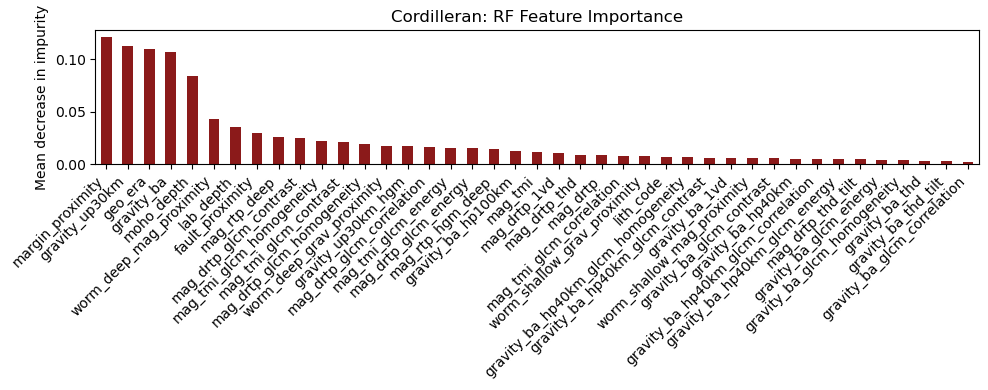

  fold 1: val AUC=0.974
  fold 2: val AUC=0.939
  fold 3: val AUC=0.940
  fold 4: val AUC=0.961
  fold 5: val AUC=0.981
[Cordilleran] DevNet 5-fold  AUC=0.959±0.017  (folds evaluated: 5/5)


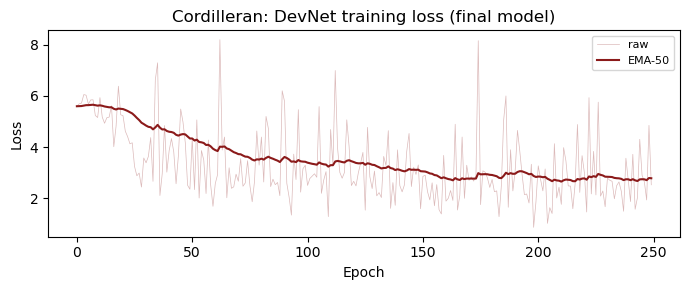

[Cordilleran] training complete.


[Superior] building features ...
  Positive: 8  |  Candidates: 19723
  extracting terrane attributes (H3 Grid) ...
  computing fault proximity ...
  computing passive margin proximity ...
  computing worm proximity ...
  sampling rasters ...
  extracting GLCM texture features ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  selecting negatives (50% cosine + 50% random) ...
  mixed selection: 200 cosine + 200 random / 19702 candidates
  final: 8 positive + 400 negative | 50 features
[Superior] RF 5-fold  AUC=0.926±0.064   AP=0.458±0.381


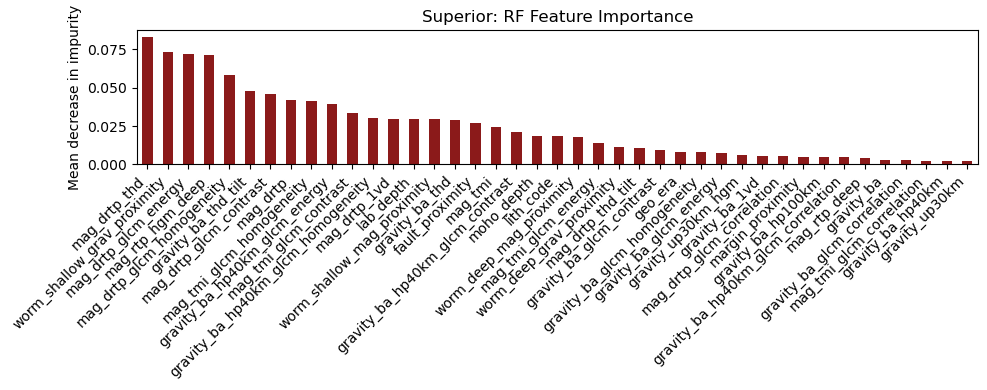

  fold 1: val AUC=0.775
  fold 2: val AUC=0.994
  fold 3: val AUC=0.512
  fold 4: val AUC=0.812
  fold 5: val AUC=1.000
[Superior] DevNet 5-fold  AUC=0.819±0.178  (folds evaluated: 5/5)


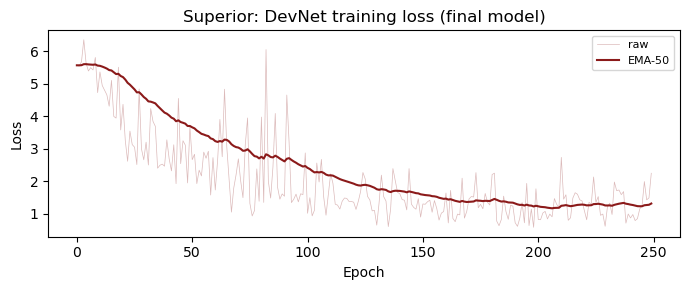

[Superior] training complete.


[Grenville] building features ...
  Positive: 6  |  Candidates: 8768
  extracting terrane attributes (H3 Grid) ...
  computing fault proximity ...
  computing passive margin proximity ...
  computing worm proximity ...
  sampling rasters ...
  extracting GLCM texture features ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  selecting negatives (50% cosine + 50% random) ...
  mixed selection: 200 cosine + 200 random / 8762 candidates
  final: 6 positive + 400 negative | 50 features
[Grenville] RF 5-fold  AUC=0.823±0.286   AP=0.625±0.460


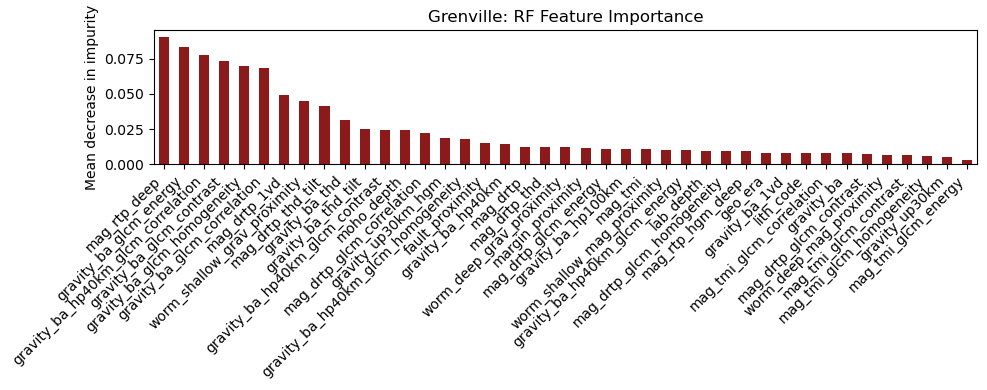

  fold 1: val AUC=0.412
  fold 2: val AUC=1.000
  fold 3: val AUC=1.000
  fold 4: val AUC=0.900
  fold 5: val AUC=0.125
[Grenville] DevNet 5-fold  AUC=0.688±0.356  (folds evaluated: 5/5)


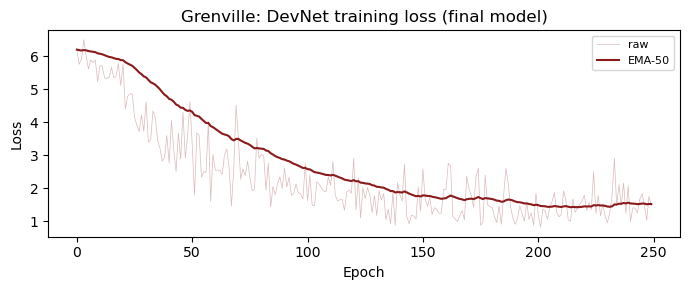

[Grenville] training complete.

All models stored in TRAINED.


In [27]:
# Build worm trees once (shared across all regions)
print('Building worm KDTrees ...')
_worm_cfg  = list(REGIONS.values())[0]['worms']
WORM_TREES = build_worm_trees(_worm_cfg)

TRAINED = {}
for name, cfg in REGIONS.items():
    raster_cols = list(CLIPPED_RASTERS[name].keys())

    pts                              = build_region(name, cfg, WORM_TREES)
    rf_model, rf_scaler, rf_imp, feat_cols = run_rf(pts, raster_cols, name)
    dn_model, dn_scaler, dn_imp, _   = run_devnet(pts, raster_cols, name)

    TRAINED[name] = {
        'pts': pts,  'feat_cols': feat_cols, 'raster_cols': raster_cols,
        'rf_model':  rf_model,  'rf_scaler':  rf_scaler,  'rf_imp':  rf_imp,
        'dn_model':  dn_model,  'dn_scaler':  dn_scaler,  'dn_imp':  dn_imp,
    }
    print(f'[{name}] training complete.\n')

print('All models stored in TRAINED.')


## 9b. Prediction Maps

Re-run **this cell only** to update plots without retraining. Models are stored in `TRAINED`.

[Cordilleran] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Cordilleran_prospectivity_no_geochem.geojson


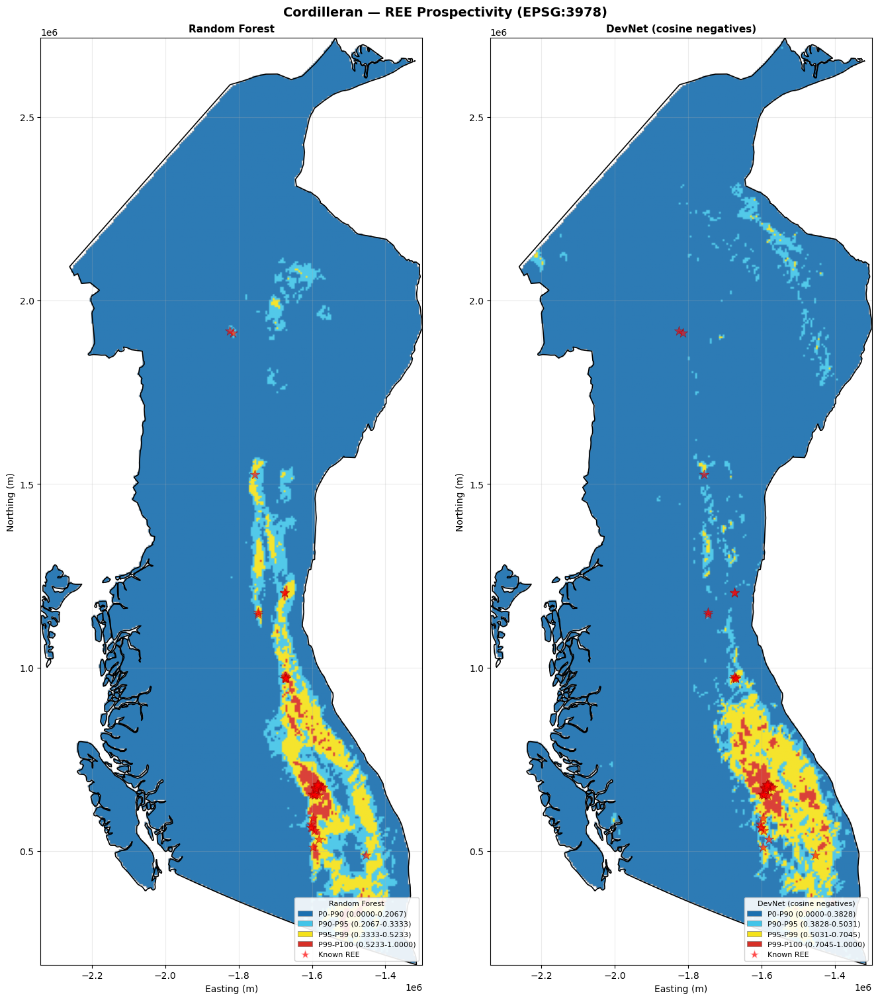

[Superior] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Superior_prospectivity_no_geochem.geojson


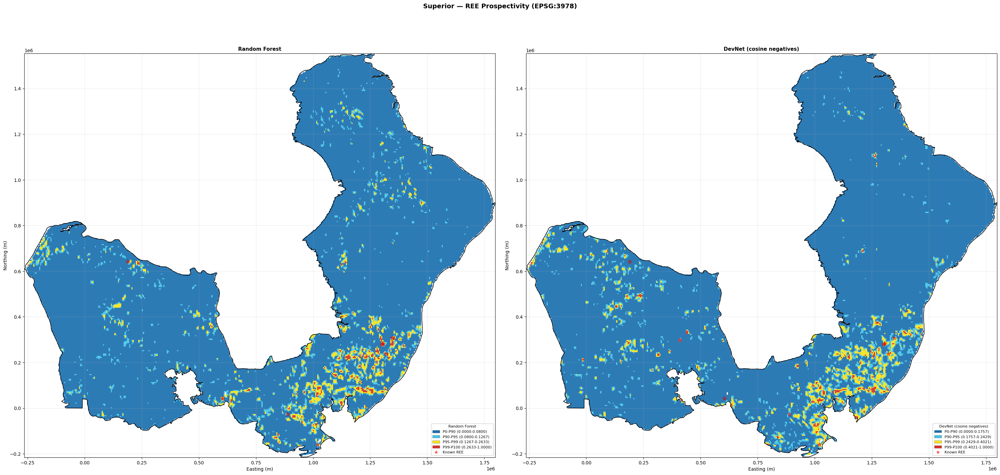

[Grenville] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Grenville_prospectivity_no_geochem.geojson


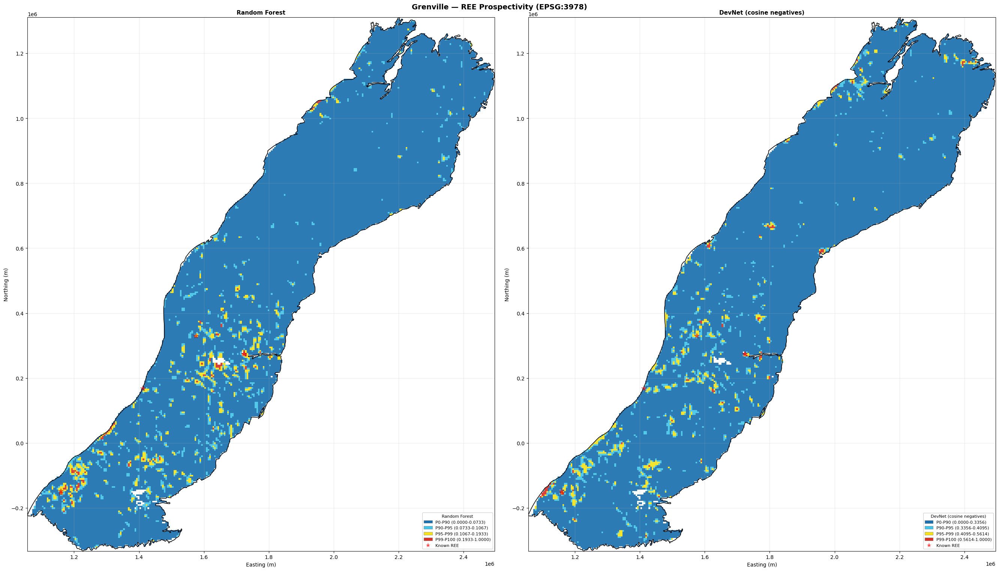

In [28]:
# ── Re-run this cell alone to update prediction maps without retraining ───
for name, cfg in REGIONS.items():
    t    = TRAINED[name]
    grid = predict_grid(
        cfg, name,
        t['rf_model'], t['rf_scaler'], t['rf_imp'], t['feat_cols'],
        t['dn_model'], t['dn_scaler'], t['dn_imp'],
        WORM_TREES,
    )
    TRAINED[name]['grid'] = grid


## 10. DevNet Ablation — Negative Sampling Comparison

Trains **Mixed** (60% cosine + 40% random) and **Pure Random** DevNets for Cordilleran, then shows a 3-way side-by-side comparison.

**Cell order:** Run *Train variants* first, then *3-way comparison*.

In [29]:
# ── DevNet Ablation: 3-Way Negative Sampling Comparison ──────────────────
# Cosine-only | Mixed 50/50 | Pure Random
# All variants: prepare datasets upfront → 5-fold CV → final model → grid

DN_EPOCHS_CMP = 250
DN_ABLATION   = {}


def _build_pts_raw(region):
    """Build full feature table with all candidates (label=-1); no selection yet."""
    cfg_r  = REGIONS[region]
    rc_r   = list(CLIPPED_RASTERS[region].keys())
    fsel   = PROXIMITY_COLS + TERRANE_COLS + rc_r + GLCM_COLS
    pts    = make_points(cfg_r, np.random.default_rng(RANDOM_SEED))
    pts    = add_terrane_h3(pts, CLIPPED_VECTORS[region].get('h3_grid'))
    pts    = add_proximity_lines(pts, cfg_r['faults'],  'fault')
    pts    = add_proximity_lines(pts, cfg_r['margins'], 'margin')
    pts    = add_proximity_worms(pts, WORM_TREES)
    pts    = add_rasters(pts, CLIPPED_RASTERS[region])
    pts    = add_glcm_features(pts, CLIPPED_RASTERS[region])
    pts    = pts[pts[rc_r].notna().any(axis=1)].reset_index(drop=True)
    fsel_r = [c for c in fsel if c in pts.columns]
    return pts, rc_r, fsel_r


def _train_abl(pts_v, rc, tag, region):
    """5-fold CV + final model + grid prediction for one ablation variant.
    Returns (proba, xs, ys, bnd_proj, dep_in, cv_mean_auc)."""
    cfg_v     = REGIONS[region]
    feat_cols = [c for c in PROXIMITY_COLS + TERRANE_COLS + rc + GLCM_COLS
                 if c in pts_v.columns]
    X_raw = pts_v[feat_cols].astype(float).values
    y     = pts_v['label'].values

    # ── 5-fold CV ─────────────────────────────────────────────────────────
    cv_skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    cv_aucs = []
    for fold, (tr_idx, va_idx) in enumerate(cv_skf.split(X_raw, y)):
        imp_f = SimpleImputer(strategy='median').fit(X_raw[tr_idx])
        sc_f  = StandardScaler().fit(imp_f.transform(X_raw[tr_idx]))
        X_tr  = sc_f.transform(imp_f.transform(X_raw[tr_idx]))
        X_va  = sc_f.transform(imp_f.transform(X_raw[va_idx]))
        y_tr, y_va = y[tr_idx], y[va_idx]
        if len(np.unique(y_va)) < 2:
            print(f'    fold {fold+1}: skipped (val has only one class)')
            continue
        va_scores_all = []
        for k in range(DN_RESTARTS):
            m_f = _train_devnet_fold(X_tr, y_tr, seed_offset=k)
            m_f.eval()
            with torch.no_grad():
                va_scores_all.append(
                    m_f(torch.tensor(X_va, dtype=torch.float32).to(DEVICE)).cpu().numpy()
                )
        va_sc = np.mean(va_scores_all, axis=0)
        cv_aucs.append(roc_auc_score(y_va, va_sc))
    cv_aucs = np.array(cv_aucs)
    cv_mean = float(cv_aucs.mean())
    print(f'  [{region} {tag}] 5-fold AUC={cv_mean:.3f}±{cv_aucs.std():.3f}  ({len(cv_aucs)}/5 folds)')

    # ── Final model on all data ────────────────────────────────────────────
    imputer = SimpleImputer(strategy='median')
    scaler  = StandardScaler()
    X_all = scaler.fit_transform(imputer.fit_transform(X_raw))
    X_tv  = torch.tensor(X_all, dtype=torch.float32).to(DEVICE)
    y_tv  = torch.tensor(y,     dtype=torch.float32).to(DEVICE)
    torch.manual_seed(DN_SEED)
    model  = DevNet(X_tv.shape[1]).to(DEVICE)
    opt    = optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    sch    = torch.optim.lr_scheduler.CosineAnnealingLR(
                 opt, T_max=DN_EPOCHS_CMP, eta_min=1e-5)
    pos_iv = np.where(y == 1)[0];  neg_iv = np.where(y == 0)[0]
    rng_dv = np.random.default_rng(DN_SEED)
    model.train()
    for _ in range(DN_EPOCHS_CMP):
        n_pb = min(len(pos_iv), DN_BATCH // 2);  n_nb = DN_BATCH - n_pb
        pi   = rng_dv.choice(pos_iv, n_pb, replace=len(pos_iv) < n_pb)
        ni   = rng_dv.choice(neg_iv, n_nb, replace=False)
        idx  = np.concatenate([pi, ni])
        opt.zero_grad()
        deviation_loss(model(X_tv[idx]), y_tv[idx]).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step();  sch.step()

    # ── Grid prediction ────────────────────────────────────────────────────
    grid_v, bnd4_v = build_grid(cfg_v)
    pts_gv = pd.DataFrame({'lat': grid_v['lat'], 'lon': grid_v['lon']})
    pts_gv = add_terrane_h3(pts_gv, CLIPPED_VECTORS[region].get('h3_grid'))
    pts_gv = add_proximity_lines(pts_gv, cfg_v['faults'],  'fault')
    pts_gv = add_proximity_lines(pts_gv, cfg_v['margins'], 'margin')
    pts_gv = add_proximity_worms(pts_gv, WORM_TREES)
    pts_gv = add_rasters(pts_gv, CLIPPED_RASTERS[region])
    pts_gv = add_glcm_features(pts_gv, CLIPPED_RASTERS[region])
    X_gvs  = scaler.transform(imputer.transform(
                 pts_gv.reindex(columns=feat_cols).astype(float).values))
    model.eval()
    with torch.no_grad():
        sc_gv = model(
            torch.tensor(X_gvs, dtype=torch.float32).to(DEVICE)
        ).cpu().numpy()
    proba_v = (sc_gv - sc_gv.min()) / (sc_gv.max() - sc_gv.min() + 1e-9)
    gp_v   = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(grid_v['lon'], grid_v['lat']), crs='EPSG:4326'
    ).to_crs(PROJECTED_CRS)
    bnd_v  = bnd4_v.to_crs(PROJECTED_CRS)
    dep_rv = pd.read_csv(cfg_v['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gv = gpd.GeoDataFrame(dep_rv,
        geometry=gpd.points_from_xy(dep_rv['Longitude'], dep_rv['Latitude']),
        crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dep_gv = dep_gv[dep_gv.within(bnd_v.unary_union)]
    return proba_v, gp_v.geometry.x.values, gp_v.geometry.y.values, bnd_v, dep_gv, cv_mean


# ── Step 1: Build all raw feature tables upfront (shared candidate pool) ──
print('Building raw feature tables for ablation (all regions) ...')
ABL_RAW = {}
for region in REGIONS:
    print(f'\n[{region}]')
    pts_raw, rc_r, fsel_r = _build_pts_raw(region)
    ABL_RAW[region] = {'pts_raw': pts_raw, 'rc': rc_r, 'fsel': fsel_r}

# ── Step 2: Apply 3 selection strategies; train all with 5-fold CV ────────
print('\nTraining all 3 variants with 5-fold CV ...')
for region in REGIONS:
    print(f'\n=== {region} ===')
    d = ABL_RAW[region]
    pts_raw, rc_r, fsel_r = d['pts_raw'], d['rc'], d['fsel']

    pts_cos = select_negatives_cosine(pts_raw.copy(), fsel_r, N_BACKGROUND)
    pts_mix = select_negatives_mixed( pts_raw.copy(), fsel_r, N_BACKGROUND, cosine_frac=0.5)
    pts_rnd = select_negatives_random(pts_raw.copy(), N_BACKGROUND)

    print('  Cosine-only ...')
    p_cos, xs_cos, ys_cos, bnd_cos, dep_cos, auc_cos = _train_abl(
        pts_cos, rc_r, 'Cosine-only', region)
    print('  Mixed 50/50 ...')
    p_mix, xs_mix, ys_mix, bnd_mix, dep_mix, auc_mix = _train_abl(
        pts_mix, rc_r, 'Mixed 50/50', region)
    print('  Pure Random ...')
    p_rnd, xs_rnd, ys_rnd, bnd_rnd, dep_rnd, auc_rnd = _train_abl(
        pts_rnd, rc_r, 'Random', region)

    DN_ABLATION[region] = {
        'cosine': {'proba': p_cos, 'xs': xs_cos, 'ys': ys_cos,
                   'bnd_proj': bnd_cos, 'dep_in': dep_cos, 'auc': auc_cos},
        'mixed':  {'proba': p_mix, 'xs': xs_mix, 'ys': ys_mix,
                   'bnd_proj': bnd_mix, 'dep_in': dep_mix, 'auc': auc_mix},
        'random': {'proba': p_rnd, 'xs': xs_rnd, 'ys': ys_rnd,
                   'bnd_proj': bnd_rnd, 'dep_in': dep_rnd, 'auc': auc_rnd},
    } 

print('\nAll regions done — run the 3-way comparison cell.')


Building raw feature tables for ablation (all regions) ...

[Cordilleran]
  Positive: 43  |  Candidates: 23318
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features

[Superior]
  Positive: 8  |  Candidates: 19723
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features

[Grenville]
  Positive: 6  |  Candidates: 8768
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features

Training all 3 variants with 5-fold CV ...

=== Cordilleran ===
  cosine selection: kept 400 / 23318 candidates
  mixed selection: 200 cosine + 200 random / 23318 candidates
  random selection: kept 400 / 23318 candidates
  Cosine-only ...
  [Cordilleran Cosine-only] 5-fold AUC=0.9

### 3-Way Comparison Map

Run after *Train variants* above.

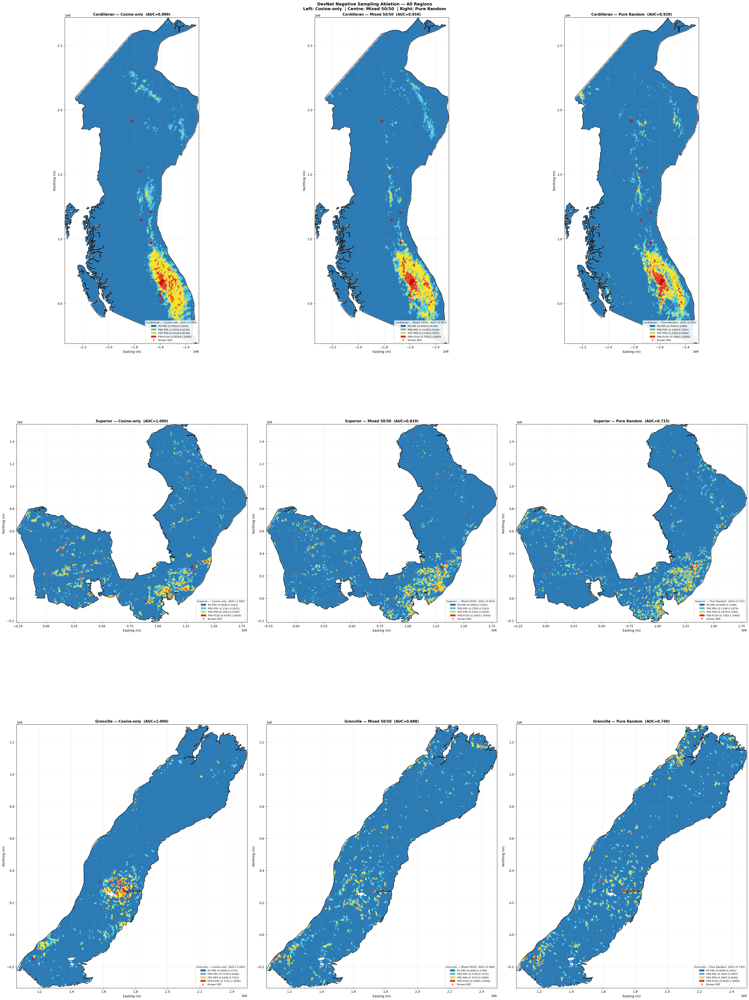

In [30]:
# ── 3-Way Comparison: All Regions × 3 Sampling Strategies ────────────────
# Rows = regions (Cordilleran / Superior / Grenville)
# Cols = Cosine-only | Mixed 50/50 | Pure Random

regions_list = list(REGIONS.keys())
n_reg = len(regions_list)

fig3, axes3 = plt.subplots(n_reg, 3, figsize=(33, 15 * n_reg),
                            constrained_layout=True)
fig3.suptitle('DevNet Negative Sampling Ablation — All Regions\n'
              'Left: Cosine-only  | Centre: Mixed 50/50  | Right: Pure Random',
              fontsize=13, fontweight='bold')

for row, name in enumerate(regions_list):
    abl_cos = DN_ABLATION[name]['cosine']
    abl_mix = DN_ABLATION[name]['mixed']
    abl_rnd = DN_ABLATION[name]['random']

    ax_row = axes3[row] if n_reg > 1 else axes3

    _prosp_panel(ax_row[0], abl_cos['proba'], abl_cos['xs'], abl_cos['ys'],
                 abl_cos['bnd_proj'], abl_cos['dep_in'],
                 f"{name} — Cosine-only  (AUC={abl_cos['auc']:.3f})")
    _prosp_panel(ax_row[1], abl_mix['proba'], abl_mix['xs'], abl_mix['ys'],
                 abl_mix['bnd_proj'], abl_mix['dep_in'],
                 f"{name} — Mixed 50/50  (AUC={abl_mix['auc']:.3f})")
    _prosp_panel(ax_row[2], abl_rnd['proba'], abl_rnd['xs'], abl_rnd['ys'],
                 abl_rnd['bnd_proj'], abl_rnd['dep_in'],
                 f"{name} — Pure Random  (AUC={abl_rnd['auc']:.3f})")

plt.show()


## 11. Representative Input Layers — Cordilleran

Four rasters (direct from clipped TIFs) + four computed features (0.2° display grid).
Colorbars use 2nd–98th percentile of valid values for contrast.

  building 0.2° grid for proximity ...


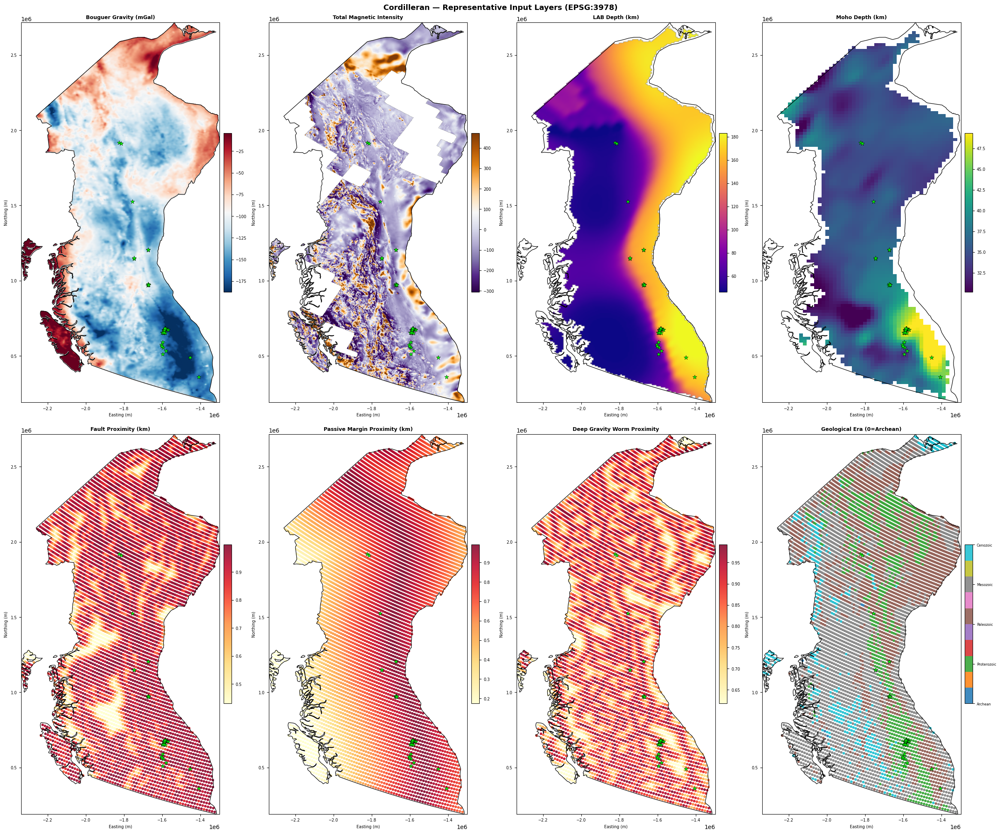

In [31]:
from rasterio.warp import reproject as _rio_reproject, Resampling as _Resampling
from rasterio.warp import calculate_default_transform as _calc_tfm
from rasterio.warp import transform_bounds as _tfm_bounds

# PROJ4 bypasses EPSG database lookup (avoids version-mismatch error)
_INPUT_CRS      = '+proj=lcc +lat_0=49 +lon_0=-95 +lat_1=49 +lat_2=77 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs'  # rasterio warp
_INPUT_CRS_EPSG = 'EPSG:3978'  # geopandas/pyproj (separate PROJ instance)


def _read_as_3978(rpath):
    """Read raster, reproject to EPSG:3978 if necessary. Returns (array, extent)."""
    with rasterio.open(rpath) as src:
        raw = src.read(1).astype(float)
        nd  = src.nodata
        if nd is not None:
            raw[raw == nd] = np.nan
        try:
            already = (src.crs.to_epsg() == 3978)
        except Exception:
            already = False
        if already:
            ext = [src.bounds.left, src.bounds.right,
                   src.bounds.bottom, src.bounds.top]
            return raw, ext
        t, w, h = _calc_tfm(src.crs, _INPUT_CRS, src.width, src.height, *src.bounds)
        dst = np.full((h, w), np.nan, dtype=np.float32)
        _rio_reproject(
            source=raw.astype(np.float32), destination=dst,
            src_transform=src.transform, src_crs=src.crs,
            dst_transform=t, dst_crs=_INPUT_CRS,
            resampling=_Resampling.bilinear, src_nodata=nd, dst_nodata=np.nan,
        )
        lft, bot, rgt, top = _tfm_bounds(src.crs, _INPUT_CRS, *src.bounds)
        return dst.astype(float), [lft, rgt, bot, top]


def plot_input_layers(name, cfg, worm_trees, clip_dir='clipped', grid_deg=0.2):
    """Show 8 representative input layers in EPSG:3978."""
    boundary_3978 = gpd.read_file(cfg['outline']).to_crs(_INPUT_CRS_EPSG)
    bx0, by0, bx1, by1 = boundary_3978.total_bounds

    dep     = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf = gpd.GeoDataFrame(
        dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326',
    ).to_crs(_INPUT_CRS_EPSG)
    dep_in = dep_gdf[dep_gdf.within(boundary_3978.unary_union)]

    def draw_boundary(ax):
        for geom in boundary_3978.geometry:
            polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
            for poly in polys:
                xs, ys = poly.exterior.xy
                ax.plot(xs, ys, 'k-', lw=0.9)
        ax.set_xlim(bx0, bx1);  ax.set_ylim(by0, by1)
        ax.set_aspect('auto')

    fig, axes = plt.subplots(2, 4, figsize=(24, 20), constrained_layout=True)
    fig.suptitle(f'{name} — Representative Input Layers (EPSG:3978)',
                 fontsize=13, fontweight='bold')

    # ── Row 1: four rasters ──────────────────────────────────────────────
    raster_panels = [
        ('gravity_ba',  'Bouguer Gravity (mGal)',   'RdBu_r'),
        ('mag_tmi',     'Total Magnetic Intensity', 'PuOr_r'),
        ('lab_depth',   'LAB Depth (km)',            'plasma'),
        ('moho_depth',  'Moho Depth (km)',           'viridis'),
    ]
    for ax, (key, title, cmap) in zip(axes[0], raster_panels):
        rpath = os.path.join(clip_dir, name, f'{key}.tif')
        if os.path.exists(rpath):
            data, ext = _read_as_3978(rpath)
            v0, v1 = np.nanpercentile(data[np.isfinite(data)], [2, 98])
            im = ax.imshow(data, extent=ext, origin='upper',
                           cmap=cmap, vmin=v0, vmax=v1, aspect='auto')
            cbar = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02, shrink=0.85)
            cbar.ax.tick_params(labelsize=7)
        else:
            ax.text(0.5, 0.5, 'file not found', transform=ax.transAxes,
                    ha='center', va='center', color='red')
        draw_boundary(ax)
        ax.scatter(dep_in.geometry.x, dep_in.geometry.y,
                   marker='*', s=60, c='lime', edgecolor='k', lw=0.4, zorder=5)
        ax.set_title(title, fontsize=9, fontweight='bold')
        ax.set_xlabel('Easting (m)', fontsize=7)
        ax.set_ylabel('Northing (m)', fontsize=7)
        ax.tick_params(labelsize=7)

    # ── Row 2: proximity / terrane features ─────────────────────────────
    print(f'  building {grid_deg}° grid for proximity ...')
    boundary_4326 = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area    = boundary_4326.unary_union
    xmn, ymn, xmx, ymx = boundary_4326.total_bounds
    xs2 = np.arange(xmn, xmx, grid_deg)
    ys2 = np.arange(ymn, ymx, grid_deg)
    xx2, yy2 = np.meshgrid(xs2, ys2)
    g2 = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx2.ravel(), yy2.ravel()), crs='EPSG:4326')
    g2 = g2[g2.within(study_area)].copy()
    pts2 = pd.DataFrame({'lat': g2.geometry.y.values, 'lon': g2.geometry.x.values})

    pts2 = add_proximity_lines(pts2, cfg['faults'],  'fault')
    pts2 = add_proximity_lines(pts2, cfg['margins'], 'margin')
    if worm_trees:
        pts2 = add_proximity_worms(pts2, worm_trees)
    pts2 = add_terrane_h3(pts2, CLIPPED_VECTORS[name].get('h3_grid'))

    # Project scatter points to EPSG:3978
    pts2_proj = gpd.GeoDataFrame(
        pts2,
        geometry=gpd.points_from_xy(pts2['lon'], pts2['lat']),
        crs='EPSG:4326',
    ).to_crs(_INPUT_CRS_EPSG)
    xs2_p = pts2_proj.geometry.x.values
    ys2_p = pts2_proj.geometry.y.values

    prox_panels = [
        ('fault_proximity',          'Fault Proximity (km)',         'YlOrRd'),
        ('margin_proximity',         'Passive Margin Proximity (km)','YlOrRd'),
        ('worm_deep_grav_proximity', 'Deep Gravity Worm Proximity',  'YlOrRd'),
        ('geo_era',                  'Geological Era (0=Archean)',   'tab10'),
    ]
    for ax, (col, title, cmap) in zip(axes[1], prox_panels):
        if col in pts2.columns and pts2[col].notna().any():
            vals = pts2[col].values.astype(float)
            if col == 'geo_era':
                sc = ax.scatter(xs2_p, ys2_p, c=vals,
                                cmap=cmap, s=12, alpha=0.85, vmin=0, vmax=4,
                                rasterized=True)
                cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02,
                                    shrink=0.85, ticks=[0, 1, 2, 3, 4])
                cbar.ax.set_yticklabels(
                    ['Archean', 'Proterozoic', 'Paleozoic', 'Mesozoic', 'Cenozoic'],
                    fontsize=6)
            else:
                v0, v1 = np.nanpercentile(vals[np.isfinite(vals)], [2, 98])
                sc = ax.scatter(xs2_p, ys2_p, c=vals,
                                cmap=cmap, vmin=v0, vmax=v1,
                                s=12, alpha=0.85, rasterized=True)
                cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.02, shrink=0.85)
                cbar.ax.tick_params(labelsize=7)
        else:
            ax.text(0.5, 0.5, f'{col}\nnot available', transform=ax.transAxes,
                    ha='center', va='center', color='grey', fontsize=8)
        draw_boundary(ax)
        ax.scatter(dep_in.geometry.x, dep_in.geometry.y,
                   marker='*', s=60, c='lime', edgecolor='k', lw=0.4, zorder=5)
        ax.set_title(title, fontsize=9, fontweight='bold')
        ax.set_xlabel('Easting (m)', fontsize=7)
        ax.set_ylabel('Northing (m)', fontsize=7)
        ax.tick_params(labelsize=7)

    plt.show()


# Run for Cordilleran only
plot_input_layers('Cordilleran', REGIONS['Cordilleran'], WORM_TREES)
